# Figure 7: fixed Fold 1 internal held-out analysis

This notebook presents the prespecified Figure 7 analysis. “Fold 1” is the
zero-based `outer_fold=1`: its 38 held-out CN participants supply saved OOF
z-scores, while non-Normal participants are evaluated with that same fixed
Figure 6 ico4 Warped-M2 prediction function. No model is refit and no z-score
from another fold is used. This is a fixed internal held-out analysis, not an
external independent validation.

## 1. Frozen sources, cohort, and model-recovery audit

In [15]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

REPO = Path.cwd().resolve()
if REPO.name == "notebooks":
    REPO = REPO.parents[2]
elif REPO.name == "figure7":
    REPO = REPO.parents[1]
elif not (REPO / "analysis_results" / "figure7").is_dir():
    raise RuntimeError("Run from repository root, figure7 directory, or its notebooks directory")
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
ROOT = REPO / "analysis_results" / "figure7"
INPUT = ROOT / "inputs"
OUTPUT = ROOT / "outputs"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

burden = pd.read_csv(OUTPUT / "participant_deviation_burden.csv", dtype={"subject_id": str})
flow = pd.read_csv(INPUT / "cohort_flow_coverage95_n313.csv", dtype={"subject_id": str})
group_results = pd.read_csv(OUTPUT / "figure7a_primary_results.csv")
cognition_results = pd.read_csv(OUTPUT / "figure7b_primary_and_diagnosis_sensitivity.csv")
robustness = pd.read_csv(OUTPUT / "robustness_results.csv")
balance = pd.read_csv(OUTPUT / "covariate_balance_by_group.csv")
all_cn = pd.read_csv(OUTPUT / "all_normal_oof_burden_cognition.csv", dtype={"subject_id": str})
all_cn_results = pd.read_csv(OUTPUT / "all_normal_oof_cognition_results.csv")
all_cn_qc = json.loads((OUTPUT / "all_normal_oof_validation.json").read_text())
fold_audit = json.loads((INPUT / "fold1_cohort_audit.json").read_text())
recovery = json.loads((OUTPUT / "model_recovery_validation.json").read_text())
analysis_qc = json.loads((OUTPUT / "analysis_validation.json").read_text())

assert fold_audit["selected_outer_fold"] == 1
assert fold_audit["fold1_heldout_cn"] == 38
assert recovery["model_refit"] is False and recovery["folds_mixed"] is False
assert set(burden.loc[burden.diagnosis_at_scan.eq("Normal"), "model_role"]) == {"fold1_heldout_cn"}
assert len(burden) == 111 and burden.subject_id.nunique() == 111

display(pd.DataFrame([{
    "coverage>=95% source": fold_audit["coverage95_source_n"],
    "Fold 1 training CN excluded": fold_audit["fold1_training_cn"],
    "Held-out CN": fold_audit["final_counts"]["Normal"],
    "MCI": fold_audit["final_counts"]["MCI"],
    "AD": fold_audit["final_counts"]["AD"],
    "Other/Impaired": fold_audit["final_counts"]["Other/Impaired non-demented"],
    "Unknown": fold_audit["final_counts"]["Unknown"],
    "Final N": fold_audit["final_n"],
}]))
display(pd.DataFrame([recovery]))

,coverage>=95% source,Fold 1 training CN excluded,Held-out CN,MCI,AD,Other/Impaired,Unknown,Final N
0,313,148,38,19,6,22,26,111


,status,outer_fold,fold_numbering,n_participants,n_nodes,n_depths,fixed_mask_positions,depth_bands,z_threshold,model_refit,folds_mixed,heldout_cn_z_source,target_z_source,recovery_positions,target_unavailable_positions_insufficient_saved_design_rank,maximum_saved_z_recovery_error,maximum_heldout_input_z_error,minimum_target_latent_variance,elapsed_seconds
0,complete,1,zero-based; selected Fold 1 is outer_fold=1,111,4687,21,98427,"{'outer': [0, 1, 2, 3, 4, 5, 6], 'middle': [7,...",2.0,False,False,saved Figure 6 Fold 1 OOF z-scores copied dire...,fixed latent mean/variance functions recovered...,98385,42,8.876233e-14,8.876233e-14,0.000032,67.641908


The fixed analysis mask contains 4,687 nodes × 21 depths. Forty-two
node–depth positions (two nodes) did not have enough saved held-out design rank
to recover a target prediction function; they remain explicitly unavailable
for targets rather than being imputed or refit. All other recovered functions
must numerically reproduce saved Fold 1 z-scores. Held-out CN always use their
stored OOF z-scores directly.

## 2. Participant-level deviation burden and covariate balance

In [16]:
display(burden[["subject_id", "diagnosis_at_scan", "age_at_scan", "SUBJECT_SEX",
                "coverage_fraction", "n_valid_positions", "positive_deviation_burden",
                "negative_deviation_burden", "total_deviation_burden"]].head())
display(balance)

,subject_id,diagnosis_at_scan,age_at_scan,SUBJECT_SEX,coverage_fraction,n_valid_positions,positive_deviation_burden,negative_deviation_burden,total_deviation_burden
0,D0029,AD,62.0,1,0.978278,96180,0.068403,0.018954,0.087357
1,D0049,Normal,63.0,2,0.991797,97461,0.016335,0.013954,0.030289
2,D0051,Normal,72.0,2,0.983423,96831,0.036579,0.019601,0.056180
3,D0052,MCI,52.0,2,0.977121,96117,0.026145,0.026541,0.052686
4,D0060,Other/Impaired non-demented,68.0,1,0.996038,98007,0.020172,0.015009,0.035181


,diagnosis,n,age_mean,age_sd,age_min,age_max,sex_code_1_n,sex_code_2_n,coverage_mean,coverage_sd,...,total_deviation_burden_mean,positive_deviation_burden_mean,negative_deviation_burden_mean,total_deviation_burden_sd,positive_deviation_burden_sd,negative_deviation_burden_sd,age_range_overlaps_cn,coverage_range_overlaps_cn,age_standardized_mean_difference_vs_cn,coverage_standardized_mean_difference_vs_cn
0,AD,6,67.500000,8.666026,54.0,78.0,1,5,0.984341,0.005034,...,0.093114,0.073098,0.020016,0.051889,0.044689,0.010882,True,True,0.898272,-0.733576
1,Normal,38,58.552632,9.400107,41.0,78.0,12,26,0.989036,0.004281,...,0.039469,0.023466,0.016004,0.023190,0.017691,0.008284,True,True,0.000000,0.000000
2,MCI,19,58.526316,9.209708,46.0,76.0,9,10,0.986405,0.008624,...,0.045533,0.020880,0.024653,0.031415,0.013135,0.021539,True,True,-0.002642,-0.411149
3,Other/Impaired non-demented,22,67.045455,8.850490,47.0,78.0,16,6,0.987062,0.008325,...,0.074010,0.042891,0.031119,0.055784,0.038820,0.022279,True,True,0.852638,-0.308564
4,Unknown,26,58.461538,10.076629,42.0,75.0,10,16,0.988376,0.005364,...,0.035186,0.017917,0.017269,0.019671,0.013643,0.009398,True,True,-0.009145,-0.103201


Total burden, the prespecified primary metric, is the participant-specific
fraction of valid positions with |z|>2. Positive and negative burdens are
directional checks. Columns and depths are never treated as independent
statistical units.

## 3. Figure 7A — held-out CN, MCI, and AD

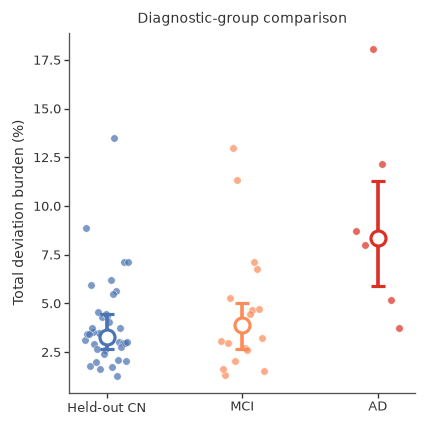

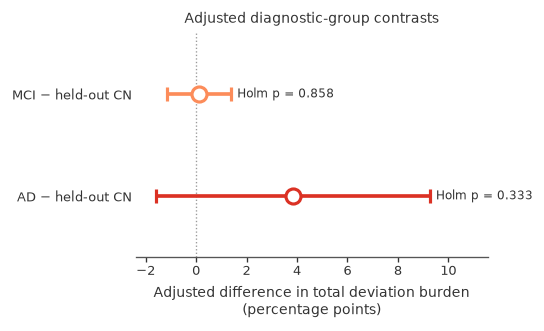

,diagnosis,n,median_percent,q25_percent,q75_percent
0,Normal,38,3.273813,2.676189,4.430767
1,MCI,19,3.899464,2.653947,5.001966
2,AD,6,8.361046,5.880070,11.306622


,predictor,n_participants,estimate_percentage_points,ci_low_percentage_points,ci_high_percentage_points,p_value,p_value_holm
0,MCI-CN,63,0.115617,-1.149789,1.381023,0.857877,0.857877
1,AD-CN,63,3.829777,-1.598725,9.258278,0.166744,0.333487


In [17]:
from qc.publication_style import PALETTE, set_publication_style, style_axes
set_publication_style()

group_order = ["Normal", "MCI", "AD"]
group_labels = {"Normal": "Held-out CN", "MCI": "MCI", "AD": "AD"}
group_colors = {"Normal": PALETTE["blue"], "MCI": PALETTE["orange"], "AD": PALETTE["red"]}
panel_a = burden[burden.diagnosis_at_scan.isin(group_order)].copy()

rng = np.random.default_rng(20261110)
summary_rows = []
for group in group_order:
    values = panel_a.loc[panel_a.diagnosis_at_scan.eq(group), "total_deviation_burden"].to_numpy(float)
    q25, median, q75 = np.quantile(values, [0.25, 0.50, 0.75])
    summary_rows.append({"diagnosis": group, "median": median, "q25": q25,
                         "q75": q75, "n": len(values)})
group_summary = pd.DataFrame(summary_rows)

fig, ax = plt.subplots(figsize=(3.6, 3.6))
for x, group in enumerate(group_order):
    values = panel_a.loc[panel_a.diagnosis_at_scan.eq(group), "total_deviation_burden"].to_numpy(float) * 100
    jitter = np.linspace(-0.16, 0.16, len(values)) if len(values) > 1 else np.array([0.0])
    rng.shuffle(jitter)
    ax.scatter(x + jitter, values, s=20, alpha=.72, color=group_colors[group],
               edgecolors="white", linewidth=.35, zorder=2)
    row = group_summary[group_summary.diagnosis.eq(group)].iloc[0]
    color = group_colors[group]
    ax.errorbar(x, row["median"] * 100,
                yerr=[[row["median"] * 100 - row.q25 * 100],
                      [row.q75 * 100 - row["median"] * 100]],
                fmt="o", color=color, mfc="white", mec=color, mew=1.9,
                capsize=4, capthick=2.2, markersize=9, linewidth=2.2, zorder=5)
ax.set_xticks(range(3), [group_labels[x] for x in group_order])
ax.set_ylabel("Total deviation burden (%)")
ax.set_title("Diagnostic-group comparison")
style_axes(ax)
fig.tight_layout()
fig.savefig(FIGURES / "Figure7A_diagnostic_group_comparison.png", dpi=600)
fig.savefig(FIGURES / "Figure7A_diagnostic_group_comparison.pdf")
plt.show()

contrast_order = ["MCI-CN", "AD-CN"]
contrast_labels = {"MCI-CN": "MCI − held-out CN", "AD-CN": "AD − held-out CN"}
contrast_colors = {"MCI-CN": group_colors["MCI"], "AD-CN": group_colors["AD"]}
fig, ax = plt.subplots(figsize=(4.5, 2.8))
for y, contrast in zip([1, 0], contrast_order):
    row = group_results.loc[group_results.predictor.eq(contrast)].iloc[0]
    color = contrast_colors[contrast]
    estimate = row.estimate_percentage_points
    low = row.ci_low_percentage_points
    high = row.ci_high_percentage_points
    ax.errorbar(estimate, y,
                xerr=[[estimate - low], [high - estimate]],
                fmt="o", color=color, mfc="white", mec=color, mew=1.9,
                capsize=4, capthick=2.2, markersize=9, linewidth=2.2, zorder=5)
    ax.text(high + .25, y, f"Holm p = {row.p_value_holm:.3f}",
            va="center", ha="left", fontsize=7, color="#333333")
ax.axvline(0, color="#999999", linewidth=.8, linestyle=":", zorder=0)
ax.set_yticks([1, 0], [contrast_labels[x] for x in contrast_order])
ax.set_xlim(group_results.ci_low_percentage_points.min() - .8,
            group_results.ci_high_percentage_points.max() + 2.3)
ax.set_ylim(-.6, 1.6)
ax.set_xlabel("Adjusted difference in total deviation burden\n(percentage points)")
ax.set_title("Adjusted diagnostic-group contrasts")
style_axes(ax)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
fig.savefig(FIGURES / "Figure7A_adjusted_group_contrasts.png", dpi=600)
fig.savefig(FIGURES / "Figure7A_adjusted_group_contrasts.pdf")
plt.show()

display(group_summary.assign(
    median_percent=lambda x: 100*x["median"],
    q25_percent=lambda x: 100*x.q25,
    q75_percent=lambda x: 100*x.q75,
)[["diagnosis", "n", "median_percent", "q25_percent", "q75_percent"]])
display(group_results[["predictor", "n_participants", "estimate_percentage_points",
                       "ci_low_percentage_points", "ci_high_percentage_points",
                       "p_value", "p_value_holm"]])

In the first figure, points are participants; large white-filled, group-colored
circles mark group medians, and the thick vertical bars with caps span the
25th–75th percentiles. The second figure displays HC3-adjusted MCI–CN and AD–CN
effects controlling age, sex code, and bilateral profile coverage: white-filled
circles are adjusted differences and horizontal bars are 95% confidence
intervals. Holm correction covers the two primary contrasts. The small AD group
is shown without concealing its uncertainty.

### Exploratory APOE ε4 analysis in the formal Figure 7A cohort

This participant-level exploratory analysis uses the formal Figure 7A cohort
(38 held-out CN, 19 MCI, and 6 AD; candidate N=63) and excludes D0128. APOE is
available for 43 participants: 21 ε4 carriers and 22 non-carriers. Two HC3
models estimate the carrier-minus-non-carrier difference in total deviation
burden: a base model adjusted for age and sex, and a second model additionally
adjusted for diagnosis. No full-genotype model or ε4-by-diagnosis interaction
is fitted because the cells are too small.

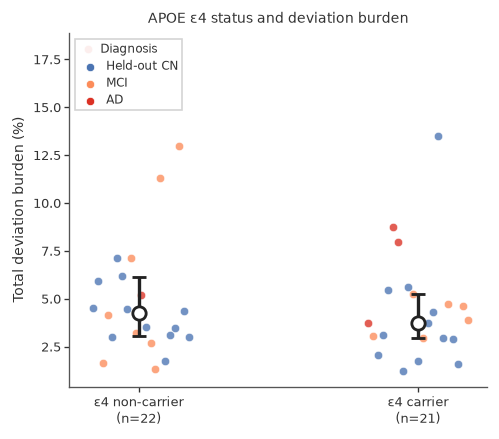

,model,n_participants,estimate_percentage_points,ci_low_percentage_points,ci_high_percentage_points,p_value
0,base,43,-0.754428,-2.849581,1.340724,0.480344
1,diagnosis_adjusted,43,-0.920313,-3.411485,1.570860,0.469024


,apoe4_status,Normal,MCI,AD,Total
0,Non-carrier,12,8,2,22
1,Carrier,12,6,3,21
2,Missing,14,5,1,20


,APOE_genotype_harmonized,Normal,MCI,AD,Total
0,2_3,3,3,0,6
1,2_4,1,1,0,2
2,3_3,9,5,2,16
3,3_4,11,5,2,18
4,4_4,0,0,1,1
5,Missing,14,5,1,20


In [18]:
apoe_participants = pd.read_csv(
    OUTPUT / "figure7a_apoe4_participant_table.csv", dtype={"subject_id": str}
)
apoe_results = pd.read_csv(OUTPUT / "figure7a_apoe4_regression_results.csv")
apoe_genotype_table = pd.read_csv(OUTPUT / "figure7a_apoe_genotype_by_diagnosis.csv")
apoe_status_table = pd.read_csv(OUTPUT / "figure7a_apoe4_status_by_diagnosis.csv")
apoe_qc = json.loads((OUTPUT / "figure7a_apoe4_validation.json").read_text())

assert apoe_qc["candidate_n"] == 63 and apoe_qc["complete_case_n"] == 43
assert apoe_qc["D0128_included"] is False
apoe_complete = apoe_participants.loc[
    apoe_participants.apoe4_status.isin(["Non-carrier", "Carrier"])
].copy()

status_order = ["Non-carrier", "Carrier"]
diagnosis_apoe_order = ["Normal", "MCI", "AD"]
rng = np.random.default_rng(20261111)
fig, ax = plt.subplots(figsize=(4.2, 3.7))
for x, status in enumerate(status_order):
    status_data = apoe_complete.loc[apoe_complete.apoe4_status.eq(status)]
    offsets = np.linspace(-0.18, 0.18, len(status_data))
    rng.shuffle(offsets)
    for offset, row in zip(offsets, status_data.itertuples(index=False)):
        ax.scatter(x + offset, row.burden_percent, s=25, alpha=.78,
                   color=group_colors[row.diagnosis_at_scan],
                   edgecolors="white", linewidth=.4, zorder=2)
    values = status_data.burden_percent.to_numpy(float)
    q25, median, q75 = np.quantile(values, [.25, .50, .75])
    ax.errorbar(x, median, yerr=[[median-q25], [q75-median]], fmt="o",
                color="#222222", mfc="white", mec="#222222", mew=1.7,
                capsize=4, capthick=2, markersize=8, linewidth=2, zorder=5)
for diagnosis in diagnosis_apoe_order:
    ax.scatter([], [], s=25, color=group_colors[diagnosis],
               label=group_labels[diagnosis], edgecolors="white", linewidth=.4)
ax.set_xticks([0, 1], ["ε4 non-carrier\n(n=22)", "ε4 carrier\n(n=21)"])
ax.set_ylabel("Total deviation burden (%)")
ax.set_title("APOE ε4 status and deviation burden")
ax.legend(loc="upper left", frameon=True, fontsize=7, title="Diagnosis",
          title_fontsize=7)
style_axes(ax)
fig.tight_layout()
fig.savefig(FIGURES / "Figure7A_exploratory_APOE4_burden.png", dpi=600)
fig.savefig(FIGURES / "Figure7A_exploratory_APOE4_burden.pdf")
plt.show()

display(apoe_results[["model", "n_participants", "estimate_percentage_points",
                      "ci_low_percentage_points", "ci_high_percentage_points",
                      "p_value"]])
display(apoe_status_table)
display(apoe_genotype_table)

The ε4 coefficient is the adjusted carrier-minus-non-carrier difference in
burden percentage points. The base estimate is −0.75 points (95% CI −2.85 to
1.34; p=0.480; N=43). After diagnosis adjustment, it is −0.92 points (95% CI
−3.41 to 1.57; p=0.469; N=43). The figure is descriptive: points are
participants colored by diagnosis, while white-filled black circles and bars
show the median and interquartile range within carrier status. Twenty
participants with missing APOE are retained in the sample table but excluded
from these complete-case regressions.

### Figure 7A sensitivity — including D0128

D0128 is added only in this sensitivity analysis because it failed visual
T1-DWI registration QC. The frozen model, age range, burden definition,
covariates, and HC3 inference are unchanged. The sensitivity Figure 7A cohort
contains 38 held-out CN, 19 MCI, and 7 AD participants (N=64).

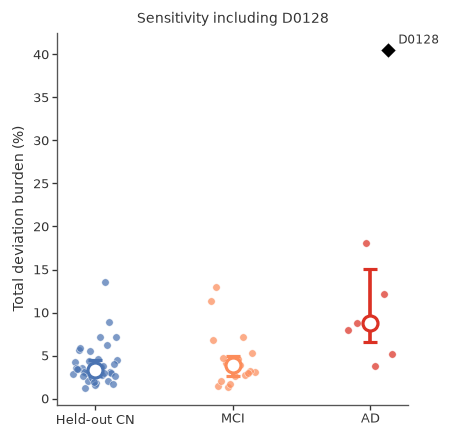

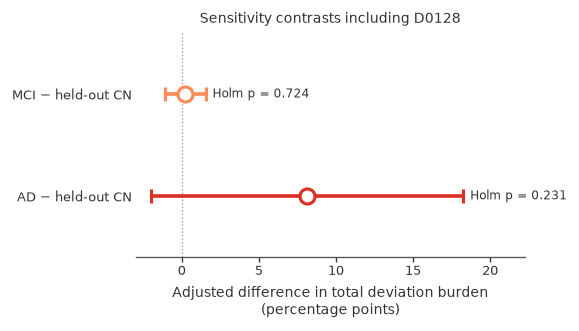

,diagnosis,n,median_percent,q25_percent,q75_percent
0,Normal,38,3.273813,2.676189,4.430767
1,MCI,19,3.899464,2.653947,5.001966
2,AD,7,8.735704,6.582176,15.108125


,predictor,n_participants,estimate_percentage_points,ci_low_percentage_points,ci_high_percentage_points,p_value,p_value_holm
0,MCI-CN,64,0.237030,-1.076357,1.550417,0.723549,0.723549
1,AD-CN,64,8.132784,-1.993643,18.259212,0.115465,0.230931


,predictor,estimate_percentage_points_primary,estimate_percentage_points_include_D0128,estimate_change_percentage_points
0,MCI-CN,0.115617,0.237030,0.121413
1,AD-CN,3.829777,8.132784,4.303008


In [19]:
sensitivity_root = ROOT / "sensitivity_include_D0128"
sensitivity_burden = pd.read_csv(
    sensitivity_root / "outputs" / "participant_deviation_burden.csv",
    dtype={"subject_id": str},
)
sensitivity_results = pd.read_csv(
    sensitivity_root / "outputs" / "figure7a_include_D0128_results.csv"
)
sensitivity_comparison = pd.read_csv(
    sensitivity_root / "outputs" / "figure7a_primary_vs_include_D0128.csv"
)
sensitivity_panel = sensitivity_burden[
    sensitivity_burden.diagnosis_at_scan.isin(group_order)
].copy()
assert len(sensitivity_panel) == 64
assert sensitivity_panel.diagnosis_at_scan.value_counts().to_dict() == {
    "Normal": 38, "MCI": 19, "AD": 7
}

rng = np.random.default_rng(20261111)
sensitivity_summary = []
fig, ax = plt.subplots(figsize=(3.8, 3.7))
for x, group in enumerate(group_order):
    group_data = sensitivity_panel.loc[
        sensitivity_panel.diagnosis_at_scan.eq(group)
    ].copy()
    regular = group_data.loc[~group_data.subject_id.eq("D0128")]
    values = regular.total_deviation_burden.to_numpy(float) * 100
    jitter = np.linspace(-0.16, 0.16, len(values)) if len(values) > 1 else np.array([0.0])
    rng.shuffle(jitter)
    ax.scatter(x + jitter, values, s=20, alpha=.72, color=group_colors[group],
               edgecolors="white", linewidth=.35, zorder=2)
    all_values = group_data.total_deviation_burden.to_numpy(float) * 100
    q25, median, q75 = np.quantile(all_values, [.25, .50, .75])
    sensitivity_summary.append({"diagnosis": group, "n": len(all_values),
                                "median_percent": median, "q25_percent": q25,
                                "q75_percent": q75})
    ax.errorbar(x, median, yerr=[[median-q25], [q75-median]], fmt="o",
                color=group_colors[group], mfc="white", mec=group_colors[group],
                mew=1.9, capsize=4, capthick=2.2, markersize=9,
                linewidth=2.2, zorder=5)
d0128 = sensitivity_panel.loc[sensitivity_panel.subject_id.eq("D0128")].iloc[0]
ax.scatter(2.13, d0128.total_deviation_burden * 100, marker="D", s=45,
           color="black", edgecolors="white", linewidth=.6, zorder=7)
ax.annotate("D0128", (2.13, d0128.total_deviation_burden * 100),
            xytext=(6, 2), textcoords="offset points", fontsize=7,
            ha="left", va="bottom")
ax.set_xticks(range(3), [group_labels[x] for x in group_order])
ax.set_ylabel("Total deviation burden (%)")
ax.set_title("Sensitivity including D0128")
style_axes(ax)
fig.tight_layout()
fig.savefig(FIGURES / "Figure7A_sensitivity_include_D0128_group_comparison.png", dpi=600)
fig.savefig(FIGURES / "Figure7A_sensitivity_include_D0128_group_comparison.pdf")
plt.show()

fig, ax = plt.subplots(figsize=(4.8, 2.8))
for y, contrast in zip([1, 0], contrast_order):
    row = sensitivity_results.loc[sensitivity_results.predictor.eq(contrast)].iloc[0]
    estimate, low, high = (row.estimate_percentage_points,
                           row.ci_low_percentage_points,
                           row.ci_high_percentage_points)
    ax.errorbar(estimate, y, xerr=[[estimate-low], [high-estimate]], fmt="o",
                color=contrast_colors[contrast], mfc="white",
                mec=contrast_colors[contrast], mew=1.9, capsize=4,
                capthick=2.2, markersize=9, linewidth=2.2, zorder=5)
    ax.text(high + .45, y, f"Holm p = {row.p_value_holm:.3f}",
            va="center", ha="left", fontsize=7, color="#333333")
ax.axvline(0, color="#999999", linewidth=.8, linestyle=":", zorder=0)
ax.set_yticks([1, 0], [contrast_labels[x] for x in contrast_order])
ax.set_xlim(sensitivity_results.ci_low_percentage_points.min() - 1.0,
            sensitivity_results.ci_high_percentage_points.max() + 4.0)
ax.set_ylim(-.6, 1.6)
ax.set_xlabel("Adjusted difference in total deviation burden\n(percentage points)")
ax.set_title("Sensitivity contrasts including D0128")
style_axes(ax)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
fig.savefig(FIGURES / "Figure7A_sensitivity_include_D0128_adjusted_contrasts.png", dpi=600)
fig.savefig(FIGURES / "Figure7A_sensitivity_include_D0128_adjusted_contrasts.pdf")
plt.show()

display(pd.DataFrame(sensitivity_summary))
display(sensitivity_results[["predictor", "n_participants",
                             "estimate_percentage_points",
                             "ci_low_percentage_points",
                             "ci_high_percentage_points",
                             "p_value", "p_value_holm"]])
display(sensitivity_comparison[["predictor",
                                "estimate_percentage_points_primary",
                                "estimate_percentage_points_include_D0128",
                                "estimate_change_percentage_points"]])

D0128 has 40.54% total deviation burden, predominantly positive. Including it
raises the adjusted AD-CN estimate from 3.83 to 8.13 percentage points; the 95%
confidence interval still crosses zero (Holm p=0.231). This result remains a
QC-qualified sensitivity analysis and does not replace the primary Figure 7A.

## 4. Figure 7B — global cognition association

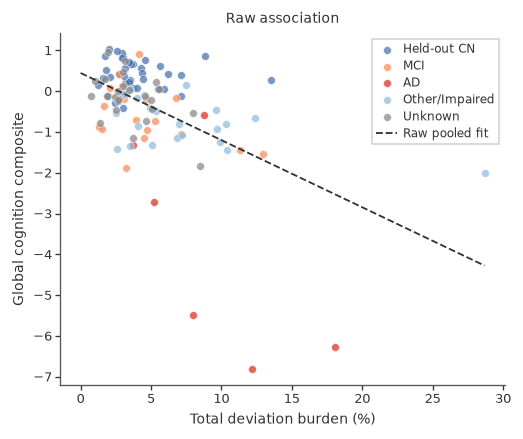

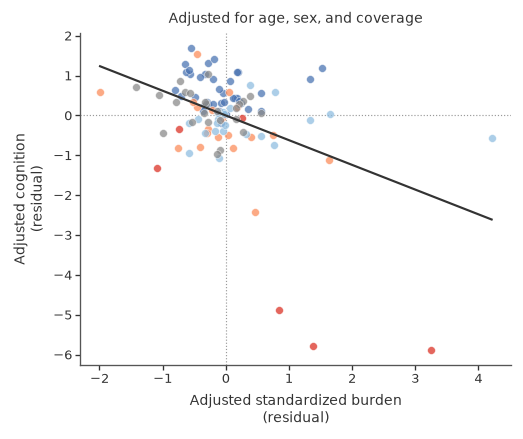

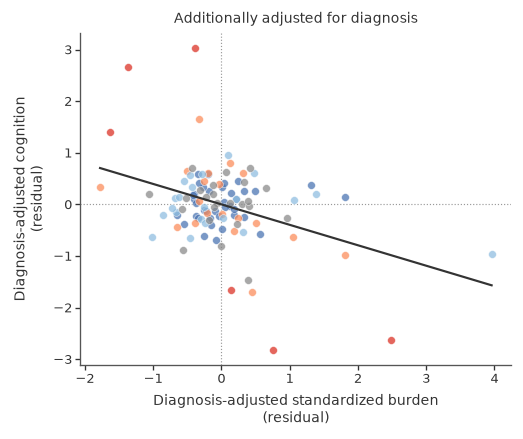

,sensitivity,n_participants,estimate,ci_low,ci_high,p_value,diagnosis_adjusted,r_squared
0,raw_unadjusted,109,-0.629029,-1.157202,-0.100856,0.019584,False,0.261375
1,primary,109,-0.619902,-1.334741,0.094937,0.089194,False,0.291686
2,primary_diagnosis_adjusted,109,-0.396083,-0.721256,-0.070910,0.016969,True,0.686459


In [20]:
diagnosis_order = ["Normal", "MCI", "AD", "Other/Impaired non-demented", "Unknown"]
diagnosis_labels = {"Normal": "Held-out CN", "MCI": "MCI", "AD": "AD",
                    "Other/Impaired non-demented": "Other/Impaired", "Unknown": "Unknown"}
diagnosis_colors = {"Normal": PALETTE["blue"], "MCI": PALETTE["orange"],
                    "AD": PALETTE["red"], "Other/Impaired non-demented": PALETTE["light_blue"],
                    "Unknown": PALETTE["gray"]}
panel_b = burden[burden.global_cognition.notna()].copy()
raw_cognition = cognition_results.loc[cognition_results.sensitivity.eq("raw_unadjusted")].iloc[0]
primary_cognition = cognition_results.loc[cognition_results.sensitivity.eq("primary")].iloc[0]
diagnosis_cognition = cognition_results.loc[
    cognition_results.sensitivity.eq("primary_diagnosis_adjusted")
].iloc[0]
panel_b["burden_z"] = (
    panel_b.total_deviation_burden - primary_cognition.burden_mean
) / primary_cognition.burden_sd
sex_indicators = pd.get_dummies(
    panel_b["SUBJECT_SEX"].astype("category"), drop_first=True, dtype=float
).to_numpy()
covariate_design = np.column_stack([
    np.ones(len(panel_b)),
    panel_b.age_at_scan.to_numpy(float),
    sex_indicators,
    panel_b.coverage_fraction.to_numpy(float),
])
def residualize(values, design=covariate_design):
    values = np.asarray(values, dtype=float)
    coefficients = np.linalg.lstsq(design, values, rcond=None)[0]
    return values - design @ coefficients

panel_b["adjusted_cognition"] = residualize(panel_b.global_cognition)
panel_b["adjusted_burden"] = residualize(panel_b.burden_z)

fig, ax = plt.subplots(figsize=(4.4, 3.7))
for group in diagnosis_order:
    d = panel_b[panel_b.diagnosis_at_scan.eq(group)]
    ax.scatter(d.total_deviation_burden * 100, d.global_cognition, s=22, alpha=.74,
               color=diagnosis_colors[group], label=diagnosis_labels[group],
               edgecolors="white", linewidth=.35)
slope, intercept = np.polyfit(panel_b.total_deviation_burden * 100,
                              panel_b.global_cognition, 1)
assert np.isclose(slope * raw_cognition.burden_sd * 100,
                  raw_cognition.estimate, rtol=0, atol=1e-10)
xgrid = np.linspace(0, panel_b.total_deviation_burden.max() * 100, 100)
ax.plot(xgrid, intercept + slope*xgrid, color="#333333", linestyle="--",
        linewidth=1.1, label="Raw pooled fit")
ax.set_xlabel("Total deviation burden (%)")
ax.set_ylabel("Global cognition composite")
ax.set_title("Raw association")
ax.legend(loc="best", frameon=True, fontsize=7)
style_axes(ax)
fig.tight_layout()
fig.savefig(FIGURES / "Figure7B_raw_global_cognition_association.png", dpi=600)
fig.savefig(FIGURES / "Figure7B_raw_global_cognition_association.pdf")
plt.show()

fig, ax = plt.subplots(figsize=(4.4, 3.7))
for group in diagnosis_order:
    d = panel_b[panel_b.diagnosis_at_scan.eq(group)]
    ax.scatter(d.adjusted_burden, d.adjusted_cognition, s=22, alpha=.74,
               color=diagnosis_colors[group], edgecolors="white", linewidth=.35)
xgrid_adjusted = np.linspace(panel_b.adjusted_burden.min(),
                             panel_b.adjusted_burden.max(), 100)
ax.plot(xgrid_adjusted, primary_cognition.estimate * xgrid_adjusted,
        color="#333333", linewidth=1.3)
adjusted_slope = np.polyfit(panel_b.adjusted_burden, panel_b.adjusted_cognition, 1)[0]
assert np.isclose(adjusted_slope, primary_cognition.estimate, rtol=0, atol=1e-10)
ax.axhline(0, color="#999999", linewidth=.7, linestyle=":", zorder=0)
ax.axvline(0, color="#999999", linewidth=.7, linestyle=":", zorder=0)
ax.set_xlabel("Adjusted standardized burden\n(residual)")
ax.set_ylabel("Adjusted cognition\n(residual)")
ax.set_title("Adjusted for age, sex, and coverage")
style_axes(ax)
fig.tight_layout()
fig.savefig(FIGURES / "Figure7B_adjusted_global_cognition_association.png", dpi=600)
fig.savefig(FIGURES / "Figure7B_adjusted_global_cognition_association.pdf")
plt.show()

diagnosis_indicators = pd.get_dummies(
    panel_b["diagnosis_at_scan"].astype("category"), drop_first=True, dtype=float
).to_numpy()
diagnosis_design = np.column_stack([covariate_design, diagnosis_indicators])
panel_b["diagnosis_adjusted_cognition"] = residualize(
    panel_b.global_cognition, diagnosis_design
)
panel_b["diagnosis_adjusted_burden"] = residualize(
    panel_b.burden_z, diagnosis_design
)

fig, ax = plt.subplots(figsize=(4.4, 3.7))
for group in diagnosis_order:
    d = panel_b[panel_b.diagnosis_at_scan.eq(group)]
    ax.scatter(d.diagnosis_adjusted_burden, d.diagnosis_adjusted_cognition,
               s=22, alpha=.74, color=diagnosis_colors[group],
               edgecolors="white", linewidth=.35)
xgrid_diagnosis = np.linspace(panel_b.diagnosis_adjusted_burden.min(),
                              panel_b.diagnosis_adjusted_burden.max(), 100)
ax.plot(xgrid_diagnosis, diagnosis_cognition.estimate * xgrid_diagnosis,
        color="#333333", linewidth=1.3)
diagnosis_slope = np.polyfit(panel_b.diagnosis_adjusted_burden,
                             panel_b.diagnosis_adjusted_cognition, 1)[0]
assert np.isclose(diagnosis_slope, diagnosis_cognition.estimate, rtol=0, atol=1e-10)
ax.axhline(0, color="#999999", linewidth=.7, linestyle=":", zorder=0)
ax.axvline(0, color="#999999", linewidth=.7, linestyle=":", zorder=0)
ax.set_xlabel("Diagnosis-adjusted standardized burden\n(residual)")
ax.set_ylabel("Diagnosis-adjusted cognition\n(residual)")
ax.set_title("Additionally adjusted for diagnosis")
style_axes(ax)
fig.tight_layout()
fig.savefig(FIGURES / "Figure7B_diagnosis_adjusted_global_cognition_association.png", dpi=600)
fig.savefig(FIGURES / "Figure7B_diagnosis_adjusted_global_cognition_association.pdf")
plt.show()

display(cognition_results[["sensitivity", "n_participants", "estimate", "ci_low",
                           "ci_high", "p_value", "diagnosis_adjusted", "r_squared"]])

The first figure is an explicitly raw participant-level display, colored by
diagnosis; the dashed line is an unadjusted pooled fit. The second is an
added-variable visualization of the primary model: cognition and standardized
burden are each residualized for age, sex code, and coverage. The third also
residualizes both variables for diagnosis and visualizes the diagnosis-adjusted
sensitivity. Each line has the coefficient in the corresponding table row.
Unknown diagnosis does not cause exclusion when cognition is observed.

### Figure 7B depth-band follow-up

Using the same 109 cognition-complete participants and the same fixed Fold 1
model, burden is recalculated within three prespecified depth bands used by
Figure 6C: outer/pial-side depths 0–6, middle depths 7–13, and inner/white-side
depths 14–20. The first check asks whether outer and total burden rank
participants similarly. The second compares standardized cognition coefficients
using the same age, sex, and coverage covariates as primary Figure 7B.

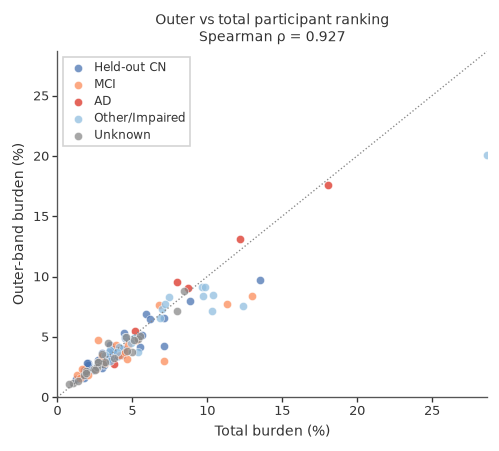

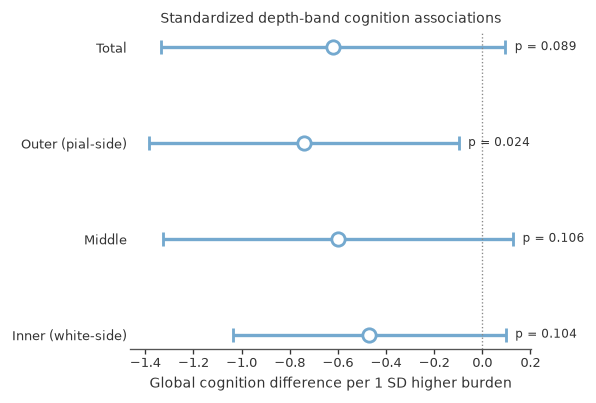

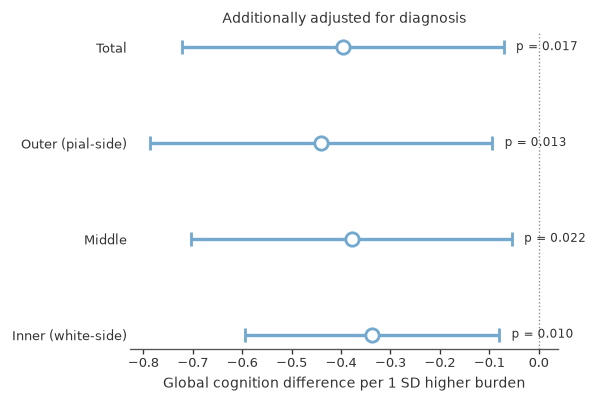

,comparison,n_participants,spearman_rho,spearman_p,kendall_tau,kendall_p,median_absolute_rank_difference,top_quartile_n,top_quartile_overlap_n,top_quartile_jaccard
0,outer_vs_total,109,0.927356,1.729621e-47,0.785593,9.566802e-34,6.0,28,26,0.866667
1,middle_vs_total,109,0.984719,4.701065e-83,0.908936,1.369923e-44,3.0,28,28,1.000000
2,inner_vs_total,109,0.963738,3.254010e-63,0.842338,1.533651e-38,5.0,28,22,0.647059


,burden,diagnosis_adjusted,n_participants,estimate_per_1sd,ci_low,ci_high,p_value,r_squared
0,total,False,109,-0.619902,-1.334741,0.094937,0.089194,0.291686
1,total,True,109,-0.396083,-0.721256,-0.070910,0.016969,0.686459
2,outer,False,109,-0.742570,-1.386478,-0.098661,0.023804,0.374307
3,outer,True,109,-0.440319,-0.786878,-0.093760,0.012766,0.697129
4,middle,False,109,-0.598553,-1.324461,0.127355,0.106072,0.278847
5,middle,True,109,-0.378485,-0.702538,-0.054431,0.022069,0.681253
6,inner,False,109,-0.470315,-1.037423,0.096794,0.104069,0.230235
7,inner,True,109,-0.337121,-0.594367,-0.079876,0.010213,0.675139


In [21]:
depth_participants = pd.read_csv(
    OUTPUT / "figure7b_depth_band_participant_table.csv", dtype={"subject_id": str}
)
depth_rank = pd.read_csv(OUTPUT / "figure7b_depth_band_rank_agreement.csv")
depth_results = pd.read_csv(OUTPUT / "figure7b_depth_band_cognition_results.csv")
depth_qc = json.loads((OUTPUT / "figure7b_depth_band_validation.json").read_text())
assert len(depth_participants) == 109 and depth_qc["model_refit"] is False

outer_rank = depth_rank.loc[depth_rank.comparison.eq("outer_vs_total")].iloc[0]
fig, ax = plt.subplots(figsize=(4.2, 3.8))
for group in diagnosis_order:
    d = depth_participants.loc[depth_participants.diagnosis_at_scan.eq(group)]
    ax.scatter(d.total_deviation_burden * 100, d.outer_burden * 100,
               s=24, alpha=.75, color=diagnosis_colors[group],
               label=diagnosis_labels[group], edgecolors="white", linewidth=.35)
limits = [0, 100 * max(depth_participants.total_deviation_burden.max(),
                       depth_participants.outer_burden.max())]
ax.plot(limits, limits, color="#888888", linestyle=":", linewidth=.8)
ax.set_xlim(limits); ax.set_ylim(limits)
ax.set_xlabel("Total burden (%)")
ax.set_ylabel("Outer-band burden (%)")
ax.set_title(f"Outer vs total participant ranking\nSpearman ρ = {outer_rank.spearman_rho:.3f}")
ax.legend(loc="best", frameon=True, fontsize=7)
style_axes(ax)
fig.tight_layout()
fig.savefig(FIGURES / "Figure7B_outer_vs_total_burden_ranking.png", dpi=600)
fig.savefig(FIGURES / "Figure7B_outer_vs_total_burden_ranking.pdf")
plt.show()

primary_depth = depth_results.loc[~depth_results.diagnosis_adjusted].copy()
order = ["total", "outer", "middle", "inner"]
labels = {"total": "Total", "outer": "Outer (pial-side)",
          "middle": "Middle", "inner": "Inner (white-side)"}
depth_color_primary = "#74A9CF"
fig, ax = plt.subplots(figsize=(5.0, 3.4))
for y, name in zip(range(3, -1, -1), order):
    row = primary_depth.loc[primary_depth.burden.eq(name)].iloc[0]
    ax.errorbar(row.estimate_per_1sd, y,
                xerr=[[row.estimate_per_1sd-row.ci_low],
                      [row.ci_high-row.estimate_per_1sd]],
                fmt="o", color=depth_color_primary, mfc="white", mec=depth_color_primary,
                mew=1.7, capsize=4, capthick=2, markersize=8, linewidth=2)
    ax.text(row.ci_high + .04, y, f"p = {row.p_value:.3f}",
            va="center", fontsize=7, color="#333333")
ax.axvline(0, color="#888888", linestyle=":", linewidth=.8)
ax.set_yticks(range(3, -1, -1), [labels[x] for x in order])
ax.set_xlabel("Global cognition difference per 1 SD higher burden")
ax.set_title("Standardized depth-band cognition associations")
style_axes(ax)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
fig.savefig(FIGURES / "Figure7B_depth_band_cognition_coefficients.png", dpi=600)
fig.savefig(FIGURES / "Figure7B_depth_band_cognition_coefficients.pdf")
plt.show()

diagnosis_depth = depth_results.loc[depth_results.diagnosis_adjusted].copy()
depth_color_diagnosis = "#74A9CF"
fig, ax = plt.subplots(figsize=(5.0, 3.4))
for y, name in zip(range(3, -1, -1), order):
    row = diagnosis_depth.loc[diagnosis_depth.burden.eq(name)].iloc[0]
    ax.errorbar(row.estimate_per_1sd, y,
                xerr=[[row.estimate_per_1sd-row.ci_low],
                      [row.ci_high-row.estimate_per_1sd]],
                fmt="o", color=depth_color_diagnosis, mfc="white", mec=depth_color_diagnosis,
                mew=1.7, capsize=4, capthick=2, markersize=8, linewidth=2)
    ax.text(row.ci_high + .025, y, f"p = {row.p_value:.3f}",
            va="center", fontsize=7, color="#333333")
ax.axvline(0, color="#888888", linestyle=":", linewidth=.8)
ax.set_yticks(range(3, -1, -1), [labels[x] for x in order])
ax.set_xlabel("Global cognition difference per 1 SD higher burden")
ax.set_title("Additionally adjusted for diagnosis")
style_axes(ax)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
fig.savefig(FIGURES / "Figure7B_depth_band_cognition_coefficients_diagnosis_adjusted.png", dpi=600)
fig.savefig(FIGURES / "Figure7B_depth_band_cognition_coefficients_diagnosis_adjusted.pdf")
plt.show()

display(depth_rank)
display(depth_results[["burden", "diagnosis_adjusted", "n_participants",
                       "estimate_per_1sd", "ci_low", "ci_high", "p_value",
                       "r_squared"]])

Outer and total burden produce highly similar rankings (Spearman ρ=0.927;
Kendall τ=0.786). Their highest-burden quartiles overlap for 26 of 28
participants. In the primary covariate model, a 1-SD higher outer burden is
associated with −0.743 global-cognition units (95% CI −1.386 to −0.099;
p=0.024), compared with −0.620 (95% CI −1.335 to 0.095; p=0.089) for total
burden. The outer-band finding is a targeted follow-up, not an independent
replication, because outer burden is a component of total burden and the
depth-band outcomes are strongly correlated. After additionally adjusting for
diagnosis, the corresponding effects are −0.396 for total burden (95% CI
−0.721 to −0.071; p=0.017) and −0.440 for outer burden (95% CI −0.787 to
−0.094; p=0.013). The diagnosis-adjusted outer result therefore remains
negative, with a confidence interval excluding zero.

## 5. Robustness checks

In [22]:
display(robustness)
display(pd.DataFrame([analysis_qc]))

,analysis,outcome,predictor,sensitivity,n_participants,estimate,ci_low,ci_high,p_value,standard_error_hc3,...,estimate_percentage_points,ci_low_percentage_points,ci_high_percentage_points,burden_mean,burden_sd,diagnosis_adjusted,covariate_adjustment,r_squared,formula,global_cognition_missing
0,Figure 7A,total_deviation_burden,MCI-CN,coverage_ge_0_98,59,0.001035,-0.012240,0.014309,0.878592,0.006773,...,0.103456,-1.223979,1.430892,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Figure 7A,total_deviation_burden,AD-CN,coverage_ge_0_98,59,0.039555,-0.023674,0.102784,0.220157,0.032260,...,3.955488,-2.367441,10.278417,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Figure 7B,global_cognition,total_deviation_burden (per 1 SD),coverage_ge_0_98,98,-0.723324,-1.440335,-0.006314,0.048016,0.365828,...,NaN,NaN,NaN,0.045863,0.031008,False,age + sex + coverage,0.319834,global_cognition ~ burden_z + age_at_scan + C(...,2.0
3,Figure 7B,global_cognition,total_deviation_burden (per 1 SD),coverage_ge_0_98_diagnosis_adjusted,98,-0.374835,-0.738277,-0.011393,0.043238,0.185433,...,NaN,NaN,NaN,0.045863,0.031008,True,age + sex + coverage + diagnosis,0.748237,global_cognition ~ burden_z + age_at_scan + C(...,2.0
4,Figure 7A,positive_deviation_burden,MCI-CN,directional_burden,63,-0.004693,-0.012793,0.003407,0.256152,0.004133,...,-0.469283,-1.279278,0.340712,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Figure 7A,positive_deviation_burden,AD-CN,directional_burden,63,0.042942,-0.000792,0.086676,0.054297,0.022314,...,4.294165,-0.079224,8.667553,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Figure 7B,global_cognition,positive_deviation_burden (per 1 SD),directional_burden,109,-0.602346,-1.235974,0.031281,0.062434,0.323285,...,NaN,NaN,NaN,0.028430,0.027458,False,age + sex + coverage,0.318649,global_cognition ~ burden_z + age_at_scan + C(...,2.0
7,Figure 7B,global_cognition,positive_deviation_burden (per 1 SD),directional_burden_diagnosis_adjusted,109,-0.336290,-0.643614,-0.028967,0.031977,0.156801,...,NaN,NaN,NaN,0.028430,0.027458,True,age + sex + coverage + diagnosis,0.676843,global_cognition ~ burden_z + age_at_scan + C(...,2.0
8,Figure 7A,negative_deviation_burden,MCI-CN,directional_burden,63,0.005849,-0.002143,0.013841,0.151480,0.004078,...,0.584900,-0.214350,1.384149,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Figure 7A,negative_deviation_burden,AD-CN,directional_burden,63,-0.004644,-0.017347,0.008060,0.473690,0.006481,...,-0.464388,-1.734728,0.805952,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,status,analysis_cohort_n,figure7a_n,figure7a_counts,figure7b_global_cognition_n,figure7b_global_cognition_missing,coverage98_n,coverage98_counts,d0271_d0285_in_analysis,d0271_d0285_exclusion_sensitivity,moca_primary_figure,statistical_unit,primary_burden,primary_group_comparisons,primary_group_multiplicity,covariance
0,complete,111,63,"{'Normal': 38, 'MCI': 19, 'AD': 6}",109,"[D0276, D0277]",100,"{'Normal': 37, 'Unknown': 24, 'Other/Impaired ...",[],not applicable; neither subject is in the pres...,False,participant,total_deviation_burden,"[MCI-CN, AD-CN]",Holm correction across two contrasts,HC3 robust standard errors


Coverage≥98%, positive/negative burden, and diagnosis-adjusted cognition models
are sensitivity analyses and do not redefine the primary outcome. D0271 and
D0285 are not members of the prespecified Fold 1 analysis cohort, so their
exclusion sensitivity is not applicable. MoCA is not used in the main figure;
all values equal to 88 are stored as missing.

## 6. Exploratory all-Normal five-fold OOF analysis

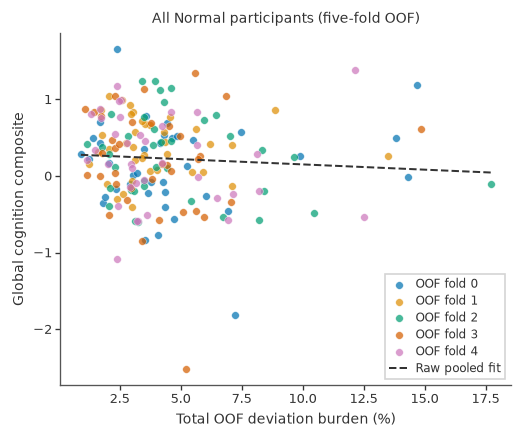

,n,age_mean,burden_mean,cognition_mean
outer_fold,,,,
0,38,59.447368,0.047415,0.112319
1,38,58.552632,0.039469,0.383269
2,37,58.972973,0.048396,0.249209
3,36,59.000000,0.039707,0.160997
4,37,59.594595,0.041460,0.230905


,sensitivity,n_participants,estimate,ci_low,ci_high,p_value,r_squared
0,primary_all_normal_oof,186,0.022004,-0.077270,0.121278,0.663977,0.166905
1,fold_fixed_effect_sensitivity,186,0.027125,-0.076926,0.131175,0.609393,0.192007


In [23]:
assert len(all_cn) == all_cn.subject_id.nunique() == 186
assert all_cn.global_cognition.notna().all()
assert all_cn.outer_fold.value_counts().sort_index().tolist() == [38, 38, 37, 36, 37]
assert all_cn_qc["model_refit"] is False

fold_colors = sns.color_palette("colorblind", 5)
fig, ax = plt.subplots(figsize=(4.4, 3.7))
for fold in range(5):
    d = all_cn[all_cn.outer_fold.eq(fold)]
    ax.scatter(d.total_deviation_burden * 100, d.global_cognition, s=21, alpha=.72,
               color=fold_colors[fold], label=f"OOF fold {fold}",
               edgecolors="white", linewidth=.3)
raw_slope, raw_intercept = np.polyfit(
    all_cn.total_deviation_burden * 100, all_cn.global_cognition, 1
)
xgrid = np.linspace(all_cn.total_deviation_burden.min() * 100,
                    all_cn.total_deviation_burden.max() * 100, 100)
ax.plot(xgrid, raw_intercept + raw_slope*xgrid, color="#333333", linestyle="--",
        linewidth=1.2, label="Raw pooled fit")
ax.set_xlabel("Total OOF deviation burden (%)")
ax.set_ylabel("Global cognition composite")
ax.set_title("All Normal participants (five-fold OOF)")
ax.legend(loc="best", frameon=True, fontsize=7)
style_axes(ax)
fig.tight_layout()
fig.savefig(FIGURES / "Figure7B_sensitivity_all_normal_oof.png", dpi=600)
fig.savefig(FIGURES / "Figure7B_sensitivity_all_normal_oof.pdf")
plt.show()

display(all_cn.groupby("outer_fold").agg(
    n=("subject_id", "size"),
    age_mean=("age_at_scan", "mean"),
    burden_mean=("total_deviation_burden", "mean"),
    cognition_mean=("global_cognition", "mean"),
))
display(all_cn_results[["sensitivity", "n_participants", "estimate", "ci_low",
                        "ci_high", "p_value", "r_squared"]])

This exploratory analysis differs from the fixed-Fold-1 Figure 7 primary
analysis. It uses all 186 frozen reference CN, but each participant contributes
only the z-scores from the fold in which that participant was held out; z-scores
are never averaged across folds. The first row adjusts for age, sex code, and
coverage. The second additionally includes fold fixed effects to check whether
small between-model offsets influence the association. The plotted dashed line
is the unadjusted pooled relationship; adjusted estimates are in the table.

### Supplementary Normal-only APOE ε4 analysis

This analysis asks a separate question from the cross-diagnostic APOE model:
among cognitively normal participants, is ε4 carrier status associated with
overall MD deviation burden? It uses all 186 frozen Figure 6 Normal
participants and each participant's z-scores from that participant's own
held-out fold. APOE is available for 128 participants, evenly divided between
64 carriers and 64 non-carriers. The HC3 model adjusts for scan age, sex, and
categorical fold: `burden (%) ~ ε4 + age + sex + fold`.

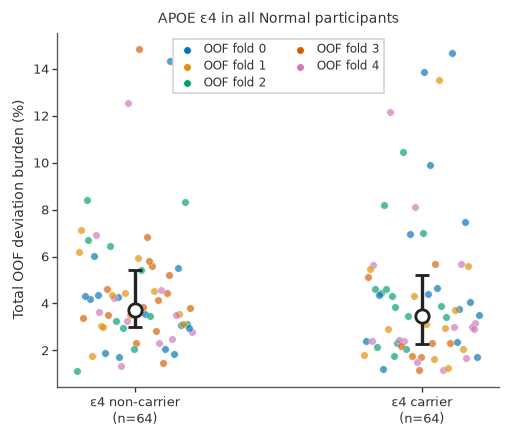

,model,n_participants,estimate_percentage_points,ci_low_percentage_points,ci_high_percentage_points,p_value,r_squared
0,age_sex_fold_adjusted,128,0.074908,-0.947887,1.097703,0.88586,0.179174


,outer_fold,Non-carrier,Carrier,Total
0,0,15,15,30
1,1,12,12,24
2,2,11,15,26
3,3,15,8,23
4,4,11,14,25


In [24]:
normal_apoe = pd.read_csv(
    OUTPUT / "all_normal_oof_apoe4_participant_table.csv", dtype={"subject_id": str}
)
normal_apoe_results = pd.read_csv(
    OUTPUT / "all_normal_oof_apoe4_regression_results.csv"
)
normal_apoe_by_fold = pd.read_csv(OUTPUT / "all_normal_oof_apoe4_by_fold.csv")
normal_apoe_qc = json.loads((OUTPUT / "all_normal_oof_apoe4_validation.json").read_text())
normal_apoe_complete = normal_apoe.loc[
    normal_apoe.apoe4_status.isin(["Non-carrier", "Carrier"])
].copy()
assert len(normal_apoe_complete) == 128
assert normal_apoe_complete.apoe4_status.value_counts().to_dict() == {
    "Non-carrier": 64, "Carrier": 64
}

fig, ax = plt.subplots(figsize=(4.3, 3.7))
rng = np.random.default_rng(20261111)
for x, status in enumerate(["Non-carrier", "Carrier"]):
    status_data = normal_apoe_complete.loc[normal_apoe_complete.apoe4_status.eq(status)]
    offsets = np.linspace(-0.20, 0.20, len(status_data))
    rng.shuffle(offsets)
    for offset, row in zip(offsets, status_data.itertuples(index=False)):
        ax.scatter(x + offset, row.burden_percent, s=20, alpha=.68,
                   color=fold_colors[int(row.outer_fold)],
                   edgecolors="white", linewidth=.3, zorder=2)
    values = status_data.burden_percent.to_numpy(float)
    q25, median, q75 = np.quantile(values, [.25, .50, .75])
    ax.errorbar(x, median, yerr=[[median-q25], [q75-median]], fmt="o",
                color="#222222", mfc="white", mec="#222222", mew=1.7,
                capsize=4, capthick=2, markersize=8, linewidth=2, zorder=5)
for fold in range(5):
    ax.scatter([], [], s=20, color=fold_colors[fold], label=f"OOF fold {fold}",
               edgecolors="white", linewidth=.3)
ax.set_xticks([0, 1], ["ε4 non-carrier\n(n=64)", "ε4 carrier\n(n=64)"])
ax.set_ylabel("Total OOF deviation burden (%)")
ax.set_title("APOE ε4 in all Normal participants")
ax.legend(loc="best", frameon=True, fontsize=7, ncol=2)
style_axes(ax)
fig.tight_layout()
fig.savefig(FIGURES / "Figure7_supplement_all_Normal_OOF_APOE4_burden.png", dpi=600)
fig.savefig(FIGURES / "Figure7_supplement_all_Normal_OOF_APOE4_burden.pdf")
plt.show()

display(normal_apoe_results[["model", "n_participants",
                             "estimate_percentage_points",
                             "ci_low_percentage_points",
                             "ci_high_percentage_points", "p_value",
                             "r_squared"]])
display(normal_apoe_by_fold)

The adjusted ε4 carrier-minus-non-carrier difference is 0.07 percentage points
(95% CI −0.95 to 1.10; p=0.886; N=128). Thus, within the cognitively normal
reference population, there is no evidence of an association between ε4
carrier status and total OOF MD deviation burden. This Normal-only result is
separate from the cross-diagnostic APOE analysis above.

### Exploratory vascular, metabolic, imaging, and biomarker screen

Using the same 186 Normal participants and five-fold OOF burden, separate HC3
models test systolic and diastolic blood pressure, diabetes history, corrected
BMI, vascular imaging findings, NfL, GFAP, p-tau181, Aβ42, Aβ40, and the
Aβ42/Aβ40 ratio. Every fitted model adjusts for visit age, sex, and categorical
fold. Blood-pressure effects are per 10 mmHg, BMI per 5 kg/m², diabetes is any
recent/active or remote/inactive history versus absent, and biomarkers are per
1 SD after log2 transformation (the Aβ42/Aβ40 ratio is standardized without
log transformation). Benjamini-Hochberg FDR is applied across fitted main
associations.

,status,source_n,exact_dwi_date_available_n,clinical_visit_date_available_n,median_absolute_scan_visit_gap_days,minimum_absolute_scan_visit_gap_days,maximum_absolute_scan_visit_gap_days,within_30_days_n,within_90_days_n,age_source,blood_pressure_special_codes_removed,diabetes_definition,imaging_code_8_treated_missing,biomarker_date_caveat,multiplicity,interaction_scope
0,complete,186,186,186,36.0,0,494,67,168,VISIT_AGE at QIAL-matched clinical visit,"[777, 888, -4]",codes 1 recent/active or 2 remote/inactive vs ...,True,values are on the matched clinical row; specim...,Benjamini-Hochberg FDR separately for main ass...,burden association heterogeneity by age; not a...


,exposure,label,available_n,missing_n,unique_nonmissing,positive_n_if_binary
0,systolic_per_10,Systolic blood pressure,185,1,82,NaN
1,diastolic_per_10,Diastolic blood pressure,185,1,58,NaN
2,diabetes_history,Diabetes history,186,0,2,22.0
3,bmi_per_5,Corrected BMI,182,4,178,NaN
4,imagmwmh_binary,Moderate WMH,49,137,2,3.0
5,imagewmh_binary,Extensive WMH,49,137,1,0.0
6,imaglinf_binary,Large infarct,49,137,1,0.0
7,imaglac_binary,Lacunar infarct,49,137,1,0.0
8,imagmich_binary,Microhemorrhage,49,137,2,3.0
9,nfl_log2_z,NfL,94,92,82,NaN


,label,unit,complete_case_n,events_or_positive_n,status,estimate_percentage_points,ci_low_percentage_points,ci_high_percentage_points,p_value,p_value_fdr_bh
0,Systolic blood pressure,10 mmHg,185,NaN,fitted,-0.088391,-0.314879,0.138096,0.444321,0.790422
1,Diastolic blood pressure,10 mmHg,185,NaN,fitted,0.049787,-0.317385,0.416959,0.790422,0.790422
2,Diabetes history,history vs absent,186,22.0,fitted,0.369677,-0.938556,1.677910,0.579687,0.790422
3,Corrected BMI,5 kg/m²,182,NaN,fitted,0.228049,-0.110624,0.566722,0.186914,0.790422
4,Moderate WMH,yes vs no,49,3.0,not_fitted_fewer_than_5_in_one_binary_cell,NaN,NaN,NaN,NaN,NaN
5,Extensive WMH,yes vs no,49,NaN,not_fitted_insufficient_data_or_variation,NaN,NaN,NaN,NaN,NaN
6,Large infarct,yes vs no,49,NaN,not_fitted_insufficient_data_or_variation,NaN,NaN,NaN,NaN,NaN
7,Lacunar infarct,yes vs no,49,NaN,not_fitted_insufficient_data_or_variation,NaN,NaN,NaN,NaN,NaN
8,Microhemorrhage,yes vs no,49,3.0,not_fitted_fewer_than_5_in_one_binary_cell,NaN,NaN,NaN,NaN,NaN
9,NfL,1 SD log2,94,NaN,fitted,-0.189986,-0.667983,0.288012,0.435974,0.790422


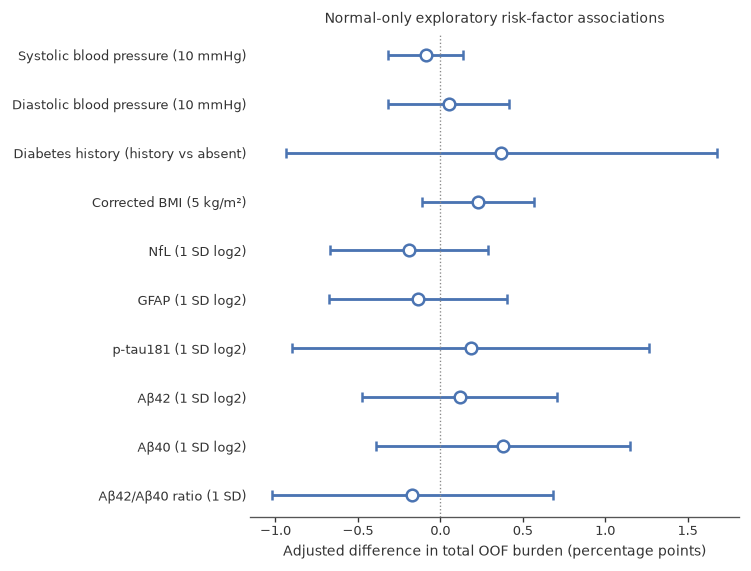

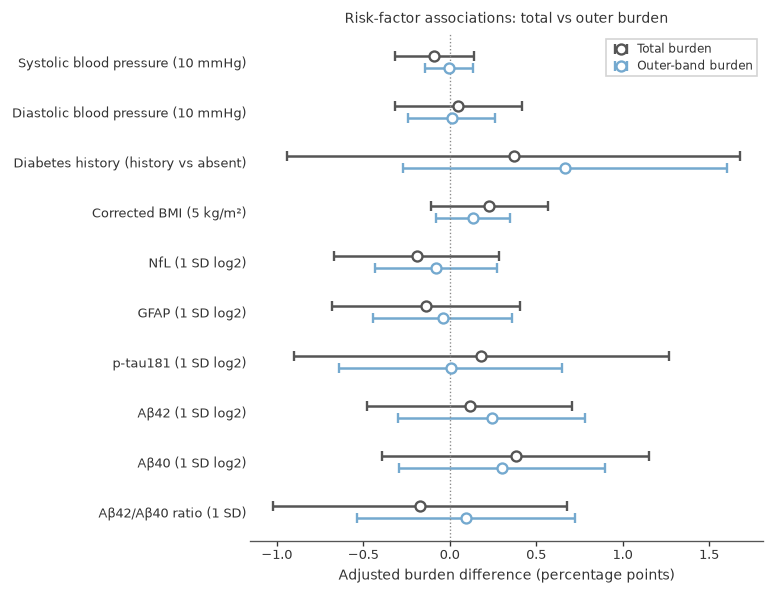

,label,unit,complete_case_n,events_or_positive_n,status,estimate_percentage_points,ci_low_percentage_points,ci_high_percentage_points,p_value,p_value_fdr_bh
0,Systolic blood pressure,10 mmHg,185,NaN,fitted,-0.004380,-0.145516,0.136757,0.951501,0.985370
1,Diastolic blood pressure,10 mmHg,185,NaN,fitted,0.012113,-0.239748,0.263974,0.924900,0.985370
2,Diabetes history,history vs absent,186,22.0,fitted,0.667204,-0.269413,1.603821,0.162657,0.947321
3,Corrected BMI,5 kg/m²,182,NaN,fitted,0.134609,-0.081308,0.350527,0.221746,0.947321
4,Moderate WMH,yes vs no,49,3.0,not_fitted_fewer_than_5_in_one_binary_cell,NaN,NaN,NaN,NaN,NaN
5,Extensive WMH,yes vs no,49,NaN,not_fitted_insufficient_data_or_variation,NaN,NaN,NaN,NaN,NaN
6,Large infarct,yes vs no,49,NaN,not_fitted_insufficient_data_or_variation,NaN,NaN,NaN,NaN,NaN
7,Lacunar infarct,yes vs no,49,NaN,not_fitted_insufficient_data_or_variation,NaN,NaN,NaN,NaN,NaN
8,Microhemorrhage,yes vs no,49,3.0,not_fitted_fewer_than_5_in_one_binary_cell,NaN,NaN,NaN,NaN,NaN
9,NfL,1 SD log2,94,NaN,fitted,-0.078752,-0.432783,0.275279,0.662850,0.985370


In [25]:
risk_results = pd.read_csv(OUTPUT / "all_normal_risk_factor_burden_results.csv")
risk_interactions = pd.read_csv(OUTPUT / "all_normal_risk_factor_age_interactions.csv")
risk_availability = pd.read_csv(OUTPUT / "all_normal_risk_factor_availability.csv")
risk_qc = json.loads((OUTPUT / "all_normal_risk_factor_validation.json").read_text())
outer_risk_results = pd.read_csv(
    OUTPUT / "all_normal_outer_risk_factor_burden_results.csv"
)
outer_risk_interactions = pd.read_csv(
    OUTPUT / "all_normal_outer_risk_factor_age_interactions.csv"
)

display(pd.DataFrame([risk_qc]))
display(risk_availability)
display(risk_results[["label", "unit", "complete_case_n",
                      "events_or_positive_n", "status",
                      "estimate_percentage_points", "ci_low_percentage_points",
                      "ci_high_percentage_points", "p_value", "p_value_fdr_bh"]])

fitted_risk = risk_results.loc[risk_results.status.eq("fitted")].copy()
fitted_risk["plot_label"] = fitted_risk.label + " (" + fitted_risk.unit + ")"
y = np.arange(len(fitted_risk))[::-1]
fig, ax = plt.subplots(figsize=(6.3, 4.8))
for position, row in zip(y, fitted_risk.itertuples(index=False)):
    ax.errorbar(row.estimate_percentage_points, position,
                xerr=[[row.estimate_percentage_points-row.ci_low_percentage_points],
                      [row.ci_high_percentage_points-row.estimate_percentage_points]],
                fmt="o", color=PALETTE["blue"], mfc="white", mec=PALETTE["blue"],
                mew=1.5, capsize=3, linewidth=1.7, markersize=7)
ax.axvline(0, color="#888888", linestyle=":", linewidth=.8)
ax.set_yticks(y, fitted_risk.plot_label)
ax.set_xlabel("Adjusted difference in total OOF burden (percentage points)")
ax.set_title("Normal-only exploratory risk-factor associations")
style_axes(ax)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
fig.savefig(FIGURES / "Figure7_supplement_Normal_risk_factor_forest.png", dpi=600)
fig.savefig(FIGURES / "Figure7_supplement_Normal_risk_factor_forest.pdf")
plt.show()

outer_fitted = outer_risk_results.loc[
    outer_risk_results.status.eq("fitted")
].copy()
comparison = fitted_risk.merge(
    outer_fitted, on=["label", "unit"], suffixes=("_total", "_outer"),
    validate="one_to_one",
)
y = np.arange(len(comparison))[::-1]
fig, ax = plt.subplots(figsize=(6.5, 5.0))
for position, row in zip(y, comparison.itertuples(index=False)):
    ax.errorbar(row.estimate_percentage_points_total, position + .12,
                xerr=[[row.estimate_percentage_points_total-row.ci_low_percentage_points_total],
                      [row.ci_high_percentage_points_total-row.estimate_percentage_points_total]],
                fmt="o", color="#555555", mfc="white", mec="#555555",
                mew=1.4, capsize=3, linewidth=1.5, markersize=6,
                label="Total burden" if position == y[0] else None)
    ax.errorbar(row.estimate_percentage_points_outer, position - .12,
                xerr=[[row.estimate_percentage_points_outer-row.ci_low_percentage_points_outer],
                      [row.ci_high_percentage_points_outer-row.estimate_percentage_points_outer]],
                fmt="o", color="#74A9CF", mfc="white", mec="#74A9CF",
                mew=1.4, capsize=3, linewidth=1.5, markersize=6,
                label="Outer-band burden" if position == y[0] else None)
ax.axvline(0, color="#888888", linestyle=":", linewidth=.8)
ax.set_yticks(y, comparison.label + " (" + comparison.unit + ")")
ax.set_xlabel("Adjusted burden difference (percentage points)")
ax.set_title("Risk-factor associations: total vs outer burden")
ax.legend(loc="best", frameon=True, fontsize=7)
style_axes(ax)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
fig.savefig(FIGURES / "Figure7_supplement_Normal_risk_factors_total_vs_outer.png", dpi=600)
fig.savefig(FIGURES / "Figure7_supplement_Normal_risk_factors_total_vs_outer.pdf")
plt.show()

display(outer_risk_results[["label", "unit", "complete_case_n",
                            "events_or_positive_n", "status",
                            "estimate_percentage_points",
                            "ci_low_percentage_points",
                            "ci_high_percentage_points", "p_value",
                            "p_value_fdr_bh"]])

The clinical row is the QIAL-matched visit used by the imaging analysis. Exact
DWI dates were recovered for all 186 participants: the median absolute
scan–visit gap is 36 days (range 0–494), with 168/186 within 90 days. Biomarker
specimen dates and assay-platform metadata are not available in this table, so
their temporal correspondence cannot be confirmed beyond the matched visit
row. Blood-pressure code 888 and imaging code 8 are treated as missing.

No fitted main association survives FDR correction. Vascular imaging variables
are primarily unavailable: only 49 participants were assessed, with three
moderate-WMH and three microhemorrhage positives; extensive WMH, large infarct,
and lacunar infarct have no positive cases. These variables are described but
not forced into unstable regression models.

The entire screen is also repeated with outer/pial-side OOF burden (depths
0–6). No outer-burden main association survives FDR correction. The gray and
light-blue estimates in the comparison figure denote total and outer burden,
respectively; they do not encode diagnostic groups.

#### Exploratory age-by-factor terms

For factors with adequate data, a second model adds `age × factor`. These terms
test whether the factor–burden association differs across age within this
cross-sectional sample. They do **not** test whether the raw MD–age slope varies
by the factor; that distinct question would require node/depth-level raw MD
models with an age-by-factor term.

,label,unit,complete_case_n,estimate_percentage_points,ci_low_percentage_points,ci_high_percentage_points,p_value,p_value_fdr_bh
0,Systolic blood pressure,per year × 10 mmHg,185,0.003842,-0.032487,0.040170,0.835807,0.843183
1,Diastolic blood pressure,per year × 10 mmHg,185,0.014050,-0.047680,0.075779,0.655531,0.843183
2,Diabetes history,per year × history vs absent,186,0.009684,-0.086261,0.105629,0.843183,0.843183
3,Corrected BMI,per year × 5 kg/m²,182,-0.012843,-0.046180,0.020495,0.450218,0.843183
4,NfL,per year × 1 SD log2,94,-0.045495,-0.115137,0.024147,0.200412,0.693931
5,GFAP,per year × 1 SD log2,92,-0.051437,-0.131538,0.028664,0.208179,0.693931
6,p-tau181,per year × 1 SD log2,50,0.024077,-0.118096,0.166251,0.739946,0.843183
7,Aβ42,per year × 1 SD log2,50,0.041086,-0.046091,0.128262,0.355633,0.843183
8,Aβ40,per year × 1 SD log2,50,0.070440,-0.032729,0.173609,0.180832,0.693931
9,Aβ42/Aβ40 ratio,per year × 1 SD,50,-0.027918,-0.157772,0.101937,0.673480,0.843183


,label,unit,complete_case_n,estimate_percentage_points,ci_low_percentage_points,ci_high_percentage_points,p_value,p_value_fdr_bh
0,Systolic blood pressure,per year × 10 mmHg,185,0.002056,-0.018568,0.022679,0.845107,0.896631
1,Diastolic blood pressure,per year × 10 mmHg,185,0.006694,-0.035354,0.048741,0.755029,0.896631
2,Diabetes history,per year × history vs absent,186,0.014218,-0.059711,0.088147,0.706221,0.896631
3,Corrected BMI,per year × 5 kg/m²,182,-0.002845,-0.028084,0.022395,0.825175,0.896631
4,NfL,per year × 1 SD log2,94,-0.018639,-0.065447,0.028169,0.435116,0.896631
5,GFAP,per year × 1 SD log2,92,-0.018325,-0.073449,0.036800,0.514700,0.896631
6,p-tau181,per year × 1 SD log2,50,0.031776,-0.047943,0.111495,0.434658,0.896631
7,Aβ42,per year × 1 SD log2,50,0.051987,-0.006745,0.110718,0.082763,0.413813
8,Aβ40,per year × 1 SD log2,50,0.062781,0.017644,0.107919,0.006409,0.064086
9,Aβ42/Aβ40 ratio,per year × 1 SD,50,-0.005603,-0.090129,0.078923,0.896631,0.896631


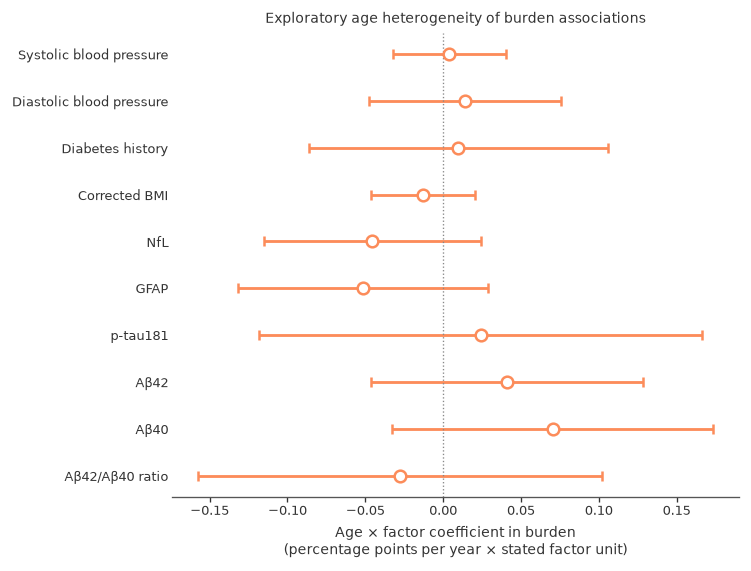

In [26]:
display(risk_interactions[["label", "unit", "complete_case_n",
                           "estimate_percentage_points",
                           "ci_low_percentage_points",
                           "ci_high_percentage_points", "p_value",
                           "p_value_fdr_bh"]])
display(outer_risk_interactions[["label", "unit", "complete_case_n",
                                 "estimate_percentage_points",
                                 "ci_low_percentage_points",
                                 "ci_high_percentage_points", "p_value",
                                 "p_value_fdr_bh"]])

y = np.arange(len(risk_interactions))[::-1]
fig, ax = plt.subplots(figsize=(6.3, 4.8))
for position, row in zip(y, risk_interactions.itertuples(index=False)):
    ax.errorbar(row.estimate_percentage_points, position,
                xerr=[[row.estimate_percentage_points-row.ci_low_percentage_points],
                      [row.ci_high_percentage_points-row.estimate_percentage_points]],
                fmt="o", color=PALETTE["orange"], mfc="white", mec=PALETTE["orange"],
                mew=1.5, capsize=3, linewidth=1.7, markersize=7)
ax.axvline(0, color="#888888", linestyle=":", linewidth=.8)
ax.set_yticks(y, risk_interactions.label)
ax.set_xlabel("Age × factor coefficient in burden\n(percentage points per year × stated factor unit)")
ax.set_title("Exploratory age heterogeneity of burden associations")
style_axes(ax)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
fig.savefig(FIGURES / "Figure7_supplement_Normal_risk_factor_age_interactions.png", dpi=600)
fig.savefig(FIGURES / "Figure7_supplement_Normal_risk_factor_age_interactions.pdf")
plt.show()

No age-by-factor term survives FDR correction for either total or outer burden.
These null exploratory burden interactions should not be interpreted as a
formal test of moderation of the raw MD–age relationship.

## 7. Concise English methods and results

In [27]:
a_mci = group_results[group_results.predictor.eq("MCI-CN")].iloc[0]
a_ad = group_results[group_results.predictor.eq("AD-CN")].iloc[0]
b_main = cognition_results[cognition_results.sensitivity.eq("primary")].iloc[0]
b_diag = cognition_results[
    cognition_results.sensitivity.eq("primary_diagnosis_adjusted")
].iloc[0]

methods = (
    f"**Methods.** We performed a fixed internal held-out analysis using the existing "
    f"Figure 6 ico4 Warped-M2 model from zero-based outer Fold 1. Saved OOF z-scores were reused for "
    f"the {fold_audit['final_counts']['Normal']} held-out CN participants; the same fixed Fold 1 "
    f"prediction function evaluated age-eligible non-Normal participants without refitting. Total "
    f"deviation burden was the participant-level fraction of valid node-depth positions with |z|>2. "
    f"Figure 7A used participant-level HC3 regression adjusted for age, sex code, and bilateral profile "
    f"coverage, with Holm correction across MCI-CN and AD-CN. Figure 7B related global cognition to "
    f"standardized total burden with the same covariates; diagnosis adjustment was a sensitivity analysis."
)

results = (
    f"**Results.** Figure 7A included {analysis_qc['figure7a_n']} participants "
    f"({analysis_qc['figure7a_counts']['Normal']} held-out CN, "
    f"{analysis_qc['figure7a_counts']['MCI']} MCI, and {analysis_qc['figure7a_counts']['AD']} AD). "
    f"The adjusted MCI-CN difference was {a_mci.estimate_percentage_points:.2f} percentage points "
    f"(95% CI {a_mci.ci_low_percentage_points:.2f} to {a_mci.ci_high_percentage_points:.2f}; "
    f"Holm p={a_mci.p_value_holm:.3g}); the AD-CN difference was "
    f"{a_ad.estimate_percentage_points:.2f} points (95% CI {a_ad.ci_low_percentage_points:.2f} to "
    f"{a_ad.ci_high_percentage_points:.2f}; Holm p={a_ad.p_value_holm:.3g}). Figure 7B included "
    f"{int(b_main.n_participants)} participants with global cognition. Per 1-SD higher total burden, "
    f"the adjusted coefficient was {b_main.estimate:.3f} (95% CI {b_main.ci_low:.3f} to "
    f"{b_main.ci_high:.3f}; p={b_main.p_value:.3g}). With diagnosis included, it was "
    f"{b_diag.estimate:.3f} (95% CI {b_diag.ci_low:.3f} to {b_diag.ci_high:.3f}; "
    f"p={b_diag.p_value:.3g}). The six-person AD estimate remains imprecise."
)
display(Markdown(methods))
display(Markdown(results))

**Methods.** We performed a fixed internal held-out analysis using the existing Figure 6 ico4 Warped-M2 model from zero-based outer Fold 1. Saved OOF z-scores were reused for the 38 held-out CN participants; the same fixed Fold 1 prediction function evaluated age-eligible non-Normal participants without refitting. Total deviation burden was the participant-level fraction of valid node-depth positions with |z|>2. Figure 7A used participant-level HC3 regression adjusted for age, sex code, and bilateral profile coverage, with Holm correction across MCI-CN and AD-CN. Figure 7B related global cognition to standardized total burden with the same covariates; diagnosis adjustment was a sensitivity analysis.

**Results.** Figure 7A included 63 participants (38 held-out CN, 19 MCI, and 6 AD). The adjusted MCI-CN difference was 0.12 percentage points (95% CI -1.15 to 1.38; Holm p=0.858); the AD-CN difference was 3.83 points (95% CI -1.60 to 9.26; Holm p=0.333). Figure 7B included 109 participants with global cognition. Per 1-SD higher total burden, the adjusted coefficient was -0.620 (95% CI -1.335 to 0.095; p=0.0892). With diagnosis included, it was -0.396 (95% CI -0.721 to -0.071; p=0.017). The six-person AD estimate remains imprecise.